# 09F — Intelligence Lab demonstration

The complete product workflow, cell by cell, **from the saved application mart only** (no warehouse, no recomputation) — the same data the interactive application reads:

1. open and validate the mart;
2. search a prospect;
3. read his profile: official tests, tracked measures, evidence labels;
4. find his stopwatch twins;
5. compare him with the top-ranked twin: what differs, is it larger than its uncertainty, where in the run;
6. relate the difference to NFL movement demands of his position — descriptively;
7. produce the scouting report (HTML) and the one-page intelligence card (PDF).

**Definition of success (Milestone 09).** A scout selects two similarly timed prospects, discovers a repeatable and properly qualified movement difference, sees the relevant NFL physical demand, understands what the comparison means, and leaves with an actionable evaluation report.

**Prerequisite.** 09E in the same `RUN_MODE`.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True            # writes the demo report and card under reports/milestone09/demo
SAVE_FIGURES = True
NUM_WORKERS = 0
ATHLETE_SEARCH = None         # part of a name, e.g. 'Smith'; None = athlete A of the first case study (a rule, not a choice)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import json

import numpy as np
import polars as pl
from IPython.display import HTML, Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import milestone09_artifacts as m9
from nflbdb.research.advanced_movement import scouting_interpretation as sin
from nflbdb.research.advanced_movement.artifacts import IntelligenceStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = IntelligenceStore(cfg, controls)
MART = m9.mart_path(store)

# ---- 1 · open and validate the mart
report = m9.validate_mart(MART)
with pl.Config(fmt_str_lengths=160, tbl_rows=-1):
    display(report)
m9.assert_valid(report)
T, EVID, MANIFEST = m9.load_mart(MART)
print(json.dumps(MANIFEST['overview'], indent=1))
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · mart `{cfg.paths.rel(MART)}` built {MANIFEST["built_at"]}'))

check,passed,detail
str,bool,str
"""declared_version""",true,"""manifest 'v1', expected 'v1'"""
"""tables_present""",true,"""all present"""
"""required_columns""",true,"""all present"""
"""rows_match_manifest""",true,"""row counts equal the manifest"""
"""fingerprints_match_manifest""",true,"""files unchanged since the manifest was written"""
"""profile_key_unique""",true,"""one profile row per athlete"""
"""displayed_athletes_exist_in_source""",true,"""every athlete of every table is in the profile table"""
"""cases_backed_by_twin_pairs""",true,"""23 case(s), each a ranked twin pair"""
"""no_case_selected_on_nfl_outcome""",true,"""no NFL outcome value entered a selection"""


{
 "n_case_types": 10,
 "n_cases": 23,
 "n_demands_measurable": 9,
 "n_measurements": 8,
 "n_nfl_episodes": 416507,
 "n_prospects": 510,
 "n_reports": 510,
 "n_tracked_attempts": 793,
 "n_tracked_prospects": 418,
 "n_twin_pairs": 3266,
 "n_twin_pairs_distinguishable": 2097,
 "positions": [
  "DB",
  "DL",
  "OL",
  "TE",
  "WR"
 ]
}


**Run mode: `full`** (FULL) · mart `warehouse/gold/advanced_movement/intelligence_v1/app_mart/v1` built 2026-10-14T13:13:05Z

## 2–3 · Search a prospect and read his profile

In [3]:
prof = T['prospect_profiles']
if ATHLETE_SEARCH:
    hits = prof.filter(pl.col('display_name').str.to_lowercase().str.contains(ATHLETE_SEARCH.lower(), literal=True) & (pl.col('n_tracked_attempts') > 0))
    display(hits.select('nfl_id', 'display_name', 'position_group', 'draft_year', 'official_forty', 'n_tracked_attempts', 'n_twins'))
    NID = hits['nfl_id'][0] if hits.height else None
else:
    NID = T['scouting_cases']['nfl_id_a'][0] if T['scouting_cases'].height else prof.filter(pl.col('n_twins') > 0)['nfl_id'][0]
P = prof.filter(pl.col('nfl_id') == NID).row(0, named=True)
NAME = P['display_name'] or str(NID)
MET = T['prospect_metrics'].filter(pl.col('nfl_id') == NID).sort('feature').to_dicts()
EV = {r['feature']: r for r in T['feature_evidence'].iter_rows(named=True)}
display(Markdown(f'### {NAME} — {P["position_group"]}, class {P["draft_year"]}\nForty **{P["official_forty"]} s** · 10-yard **{P["official_ten"]} s** · '
                 f'{P["weight"]} lb · {P["height"]} in · recording evidence **{P["evidence_tier"]}**'))
with pl.Config(tbl_rows=-1, tbl_width_chars=220):
    display(pl.DataFrame([{'measure': m['label'], 'value': m['value'], 'unit': m['unit'], 'se': m['standard_error'], 'attempts': m['n_attempts'],
                           'raw_pct_position': m['pct_position'], 'evidence': EV.get(m['feature'], {}).get('evidence_status')} for m in MET]))

### Anthony Bradford — OL, class 2023
Forty **5.08 s** · 10-yard **1.74 s** · 332.0 lb · 76.0 in · recording evidence **high**

measure,value,unit,se,attempts,raw_pct_position,evidence
str,f64,str,f64,i64,f64,str
"""band acceleration 2 → 4 yd/s""",4.597696,"""yd/s²""",0.312104,2,43.617021,"""unstable"""
"""band acceleration 4 → 6 yd/s""",3.72608,"""yd/s²""",0.312086,2,27.659574,"""unstable"""
"""band acceleration 6 → 8 yd/s""",1.897172,"""yd/s²""",0.275087,2,31.914894,"""moderately_repeatable_partly_b…"
"""speed at 10 yd""",7.593242,"""yd/s""",0.100194,2,23.404255,"""moderately_repeatable_partly_b…"
"""speed at 20 yd""",9.113379,"""yd/s""",0.057848,2,74.468085,"""repeatable_mostly_stopwatch"""
"""speed at 30 yd""",9.300416,"""yd/s""",0.061148,2,52.12766,"""repeatable_mostly_stopwatch"""
"""speed development 4 → 8 yd/s""",1.5918,"""s""",0.078617,2,67.021277,"""repeatable_beyond_official"""
"""tracked top speed (p95)""",9.33701,"""yd/s""",0.06368,2,48.93617,"""repeatable_beyond_official"""


## 4–5 · His stopwatch twins, and the comparison with the top-ranked one

pair_id,name_a,name_b,forty_a,forty_b,ten_matched,body_matched,n_distinguishable,max_abs_z,top_feature
str,str,str,f64,f64,bool,bool,i64,f64,str
"""55973-57240""","""Anthony Bradford""","""Mason McCormick""",5.08,5.08,true,false,5,10.670198,"""acc_6_8"""
"""55973-55982""","""Anthony Bradford""","""Sidy Sow""",5.08,5.07,false,true,2,5.500364,"""top_speed"""
"""55973-57126""","""Anthony Bradford""","""Joe Alt""",5.08,5.05,true,false,5,5.144019,"""time_4_8"""
"""55973-56451""","""Anthony Bradford""","""Earl Bostick""",5.08,5.05,true,false,3,4.396957,"""top_speed"""
"""55973-58373""","""Anthony Bradford""","""Drew Kendall""",5.08,5.05,false,false,4,3.702317,"""top_speed"""
"""55973-57284""","""Anthony Bradford""","""Jacob Monk""",5.08,5.09,false,false,2,3.312645,"""speed_10yd"""
"""55913-55973""","""Cody Mauch""","""Anthony Bradford""",5.08,5.08,false,false,4,3.071664,"""top_speed"""
"""55973-58231""","""Anthony Bradford""","""Josh Conerly""",5.08,5.05,true,false,3,2.998788,"""speed_10yd"""
"""55973-58898""","""Anthony Bradford""","""Clay Webb""",5.08,5.11,true,false,1,2.546612,"""speed_20yd"""


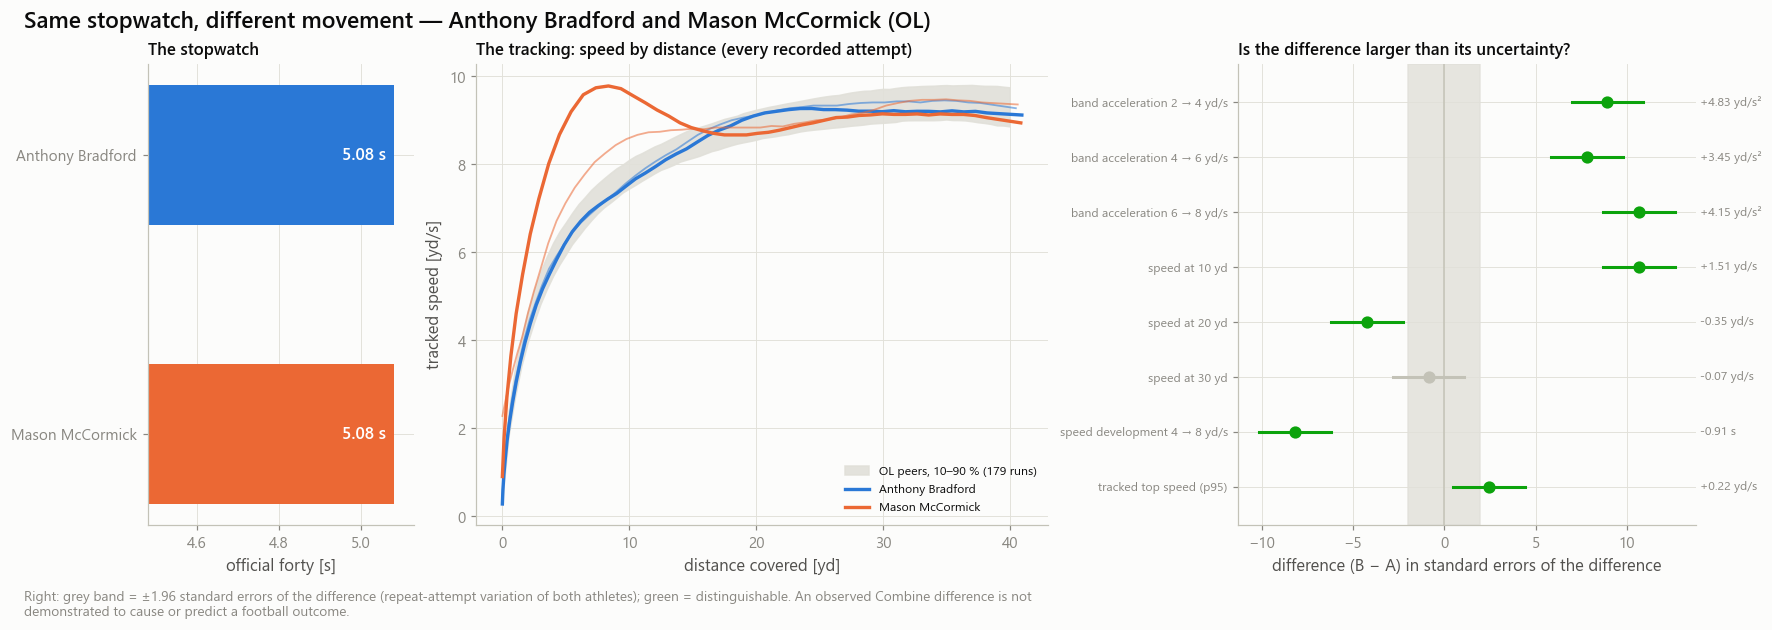

**Observation**
- Anthony Bradford and Mason McCormick (OL) ran official forty times of 5.08 s and 5.08 s — 0.00 s apart.
- Their official 10-yard splits are 1.74 s and 1.71 s.
- band acceleration 6 → 8 yd/s: 1.90 yd/s² versus 6.05 yd/s² — a difference of +4.15 yd/s² [+3.39, +4.91], larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.
- speed at 10 yd: 7.59 yd/s versus 9.10 yd/s — a difference of +1.51 yd/s [+1.23, +1.79], larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.
- speed development 4 → 8 yd/s: 1.59 s versus 0.68 s — a difference of -0.91 s [-1.13, -0.69], larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.
- 1 other feature(s) show a difference that is inside the measurement uncertainty and should not be read as a difference.

**Potential football relevance**
- The measured difference sits in late acceleration and high speed (above about 6 yd/s). That phase may be physically related to reaching and holding high speed over distance: long pursuits and movements down the field.
- The measured difference sits in early acceleration (first steps, below about 4 yd/s). That phase may be physically related to movements that start from rest or near rest: the first steps after the snap and short-area starts.
- The measured difference sits in mid-sprint speed development (about 4 to 8 yd/s). That phase may be physically related to building speed while already moving: movements that develop over several yards after the first steps.
- The corresponding football advantage has not been established.

**Scouting follow-up**
- Film — compare both prospects on screens and long pursuit after a turnover.
- Film — compare both prospects on the first steps of a pull or a set.
- Film — compare both prospects on pulls and climbs to the second level.
- Testing — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.
- Testing — timed starts over 0–5 and 0–10 yd with split timing, at least two repetitions, recorded from before the first movement.
- Testing — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.

**Limitations**
- An observed Combine difference is not demonstrated to cause or predict a football outcome.
- One drill, at maximal effort, from rest, without pads: game movement depends on role, opportunity and context.
- Recording evidence is below the high tier for Mason McCormick: read the comparison with that in mind.

In [4]:
TW = T['stopwatch_twins']
mine = TW.filter((pl.col('nfl_id_a') == NID) | (pl.col('nfl_id_b') == NID)).sort('max_abs_z', descending=True, nulls_last=True)
display(mine.select('pair_id', 'name_a', 'name_b', 'forty_a', 'forty_b', 'ten_matched', 'body_matched', 'n_distinguishable', 'max_abs_z', 'top_feature').head(10))
PAIR = mine.row(0, named=True) if mine.height else None
if PAIR is None:
    print('no stopwatch twin for this prospect: comparison skipped')
else:
    D = T['twin_differences'].filter(pl.col('pair_id') == PAIR['pair_id']).sort('feature').to_dicts()
    C = T['combine_attempt_curves']
    curve = lambda i: [(g['dist_yd'].to_numpy().astype(float), g['speed'].to_numpy().astype(float)) for _, g in
                       C.filter(pl.col('nfl_id') == i).sort('attempt_order', 'frame').partition_by(['attempt_order'], as_dict=True, maintain_order=True).items()]
    B = T['position_curve_bands'].filter(pl.col('position_group') == PAIR['position_group']).sort('dist_yd')
    BAND = {'grid': B['dist_yd'].to_numpy(), 'q10': B['q10'].to_numpy(), 'q50': B['q50'].to_numpy(), 'q90': B['q90'].to_numpy(), 'n': int(B['n_runs'][0])} if B.height else None
    names = (PAIR['name_a'], PAIR['name_b'])
    fig = ifg.fig_twin_story(PAIR, {names[0]: curve(PAIR['nfl_id_a']), names[1]: curve(PAIR['nfl_id_b'])}, BAND, D)
    store.show(fig, f'AM09F_01_demo_twin_story_{PAIR["pair_id"]}', {}, publication=True, source='application mart', n='two athletes')
    read = sin.pair_reading(PAIR, D)
    display(Markdown('\n\n'.join('**' + k + '**\n' + '\n'.join('- ' + s for s in v) for k, v in read.items())))

## 6 · The NFL demands of his position — descriptively

demand_id,n_dimensions,mean_coverage,coverage_lo,coverage_hi,state
str,i64,f64,f64,f64,str
"""accel_low""",2,99.27335,94.544534,99.751349,"""supported"""
"""accel_mid""",1,100.0,100.0,100.0,"""supported"""
"""transition_high""",0,null,null,null,"""abstain_thin_nfl_reference"""
"""sustained_high""",1,100.0,100.0,100.0,"""supported"""
"""speed_maintenance""",0,null,null,null,"""unsupported_by_forty"""
"""braking""",0,null,null,null,"""unsupported_by_forty"""
"""reaccel_after_brake""",0,null,null,null,"""unsupported_by_forty"""
"""redirection""",0,null,null,null,"""unsupported_by_forty"""
"""repeated_change""",0,null,null,null,"""unsupported_by_forty"""


demand_id,label,n_episodes,n_athletes,episodes_per_100_plays,supported
str,str,i64,i64,f64,bool
"""accel_low""","""acceleration from low speed""",67409,90,81.405937,true
"""accel_mid""","""acceleration from intermediate speed""",2208,83,2.666473,true
"""braking""","""braking and deceleration""",5085,84,6.140859,true
"""reaccel_after_brake""","""acceleration following deceleration""",590,74,0.712509,true
"""redirection""","""directional redirection""",392,65,0.473396,true
"""repeated_change""","""repeated speed-change sequence""",1098,78,1.325991,true
"""speed_maintenance""","""speed maintenance""",1747,84,2.109751,true
"""sustained_high""","""sustained high-speed running""",60,29,0.072459,true
"""transition_high""","""transition into high-speed running""",2,2,0.002415,false


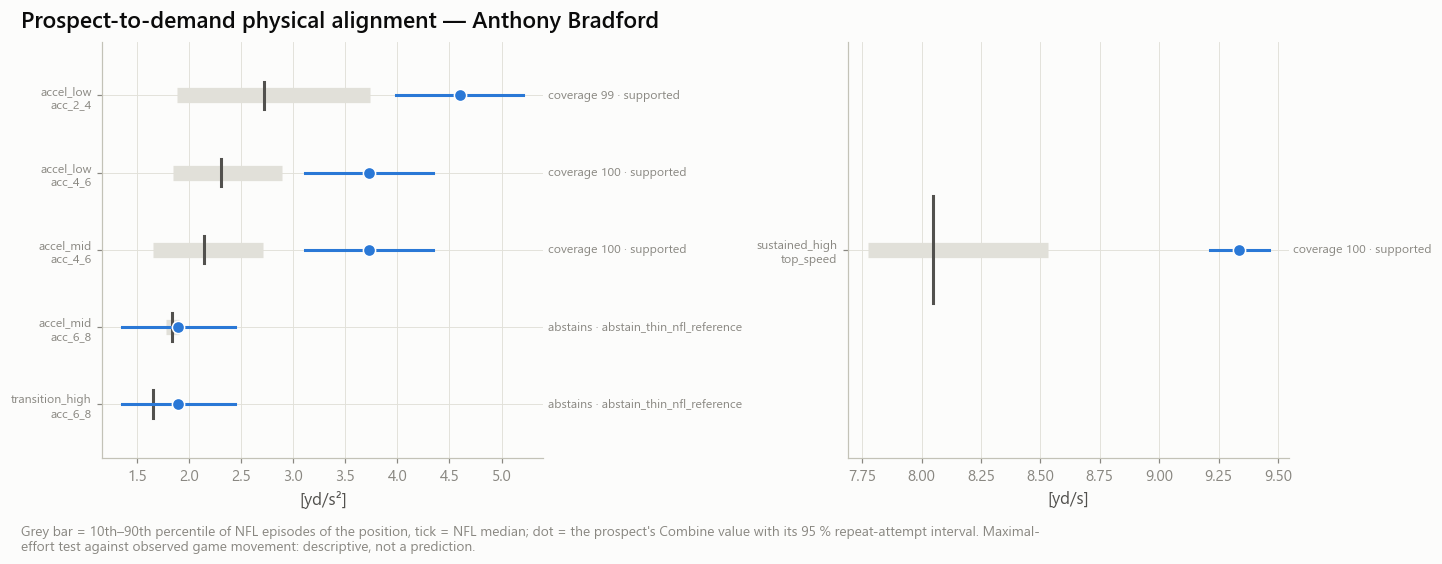

In [5]:
MAT = T['movement_similarity_matrix'].filter(pl.col('nfl_id') == NID).to_dicts()
SIM = T['movement_similarity'].filter((pl.col('nfl_id') == NID) & (pl.col('dimension') != '—')).to_dicts()
with pl.Config(tbl_rows=-1, tbl_width_chars=200, fmt_str_lengths=80):
    display(T['movement_similarity_matrix'].filter(pl.col('nfl_id') == NID).select('demand_id', 'n_dimensions', 'mean_coverage', 'coverage_lo', 'coverage_hi', 'state'))
    display(T['nfl_movement_demands'].filter(pl.col('position_group') == P['position_group']).select('demand_id', 'label', 'n_episodes', 'n_athletes', 'episodes_per_100_plays', 'supported'))
store.show(ifg.fig_alignment(SIM, NAME), f'AM09F_02_demo_alignment_{NID}', {}, publication=True, source='application mart', n='one prospect')

## 7 · The scouting report and the one-page intelligence card

**Prospect summary**
- Anthony Bradford — OL, draft class 2023. Recording evidence tier: high.

**Official testing**
- Forty-yard dash 5.08 s; 10-yard split 1.74 s; weight 332 lb; height 76.0 in.

**Tracking insights**
- band acceleration 2 → 4 yd/s: 4.60 yd/s² ± 0.61 over 2 attempt(s); raw position percentile 44 of 94 — unstable.
- band acceleration 4 → 6 yd/s: 3.73 yd/s² ± 0.61 over 2 attempt(s); raw position percentile 28 of 94 — unstable.
- band acceleration 6 → 8 yd/s: 1.90 yd/s² ± 0.54 over 2 attempt(s); raw position percentile 32 of 94 — moderately_repeatable_partly_beyond_stopwatch.
- speed at 10 yd: 7.59 yd/s ± 0.20 over 2 attempt(s); raw position percentile 23 of 94 — moderately_repeatable_partly_beyond_stopwatch.
- speed at 20 yd: 9.11 yd/s ± 0.11 over 2 attempt(s); raw position percentile 74 of 94 — repeatable_mostly_stopwatch.
- speed at 30 yd: 9.30 yd/s ± 0.12 over 2 attempt(s); raw position percentile 52 of 94 — repeatable_mostly_stopwatch.
- speed development 4 → 8 yd/s: 1.59 s ± 0.15 over 2 attempt(s); raw position percentile 67 of 94 — repeatable_beyond_official.
- tracked top speed (p95): 9.34 yd/s ± 0.12 over 2 attempt(s); raw position percentile 49 of 94 — repeatable_beyond_official.

**Matched prospects (stopwatch twins)**
- Mason McCormick: forty 0.00 s apart; 5 distinguishable curve feature(s), largest in acc_6_8.
- Sidy Sow: forty 0.01 s apart; 2 distinguishable curve feature(s), largest in top_speed.
- Joe Alt: forty 0.03 s apart; 5 distinguishable curve feature(s), largest in time_4_8.
- Earl Bostick: forty 0.03 s apart; 3 distinguishable curve feature(s), largest in top_speed.
- Drew Kendall: forty 0.03 s apart; 4 distinguishable curve feature(s), largest in top_speed.

**Movement-demand correspondence**
- accel_low: measured Combine value at or above 99 % of observed NFL episodes of this position [95, 100] over 2 shared dimension(s) — descriptive similarity only.
- accel_mid: measured Combine value at or above 100 % of observed NFL episodes of this position [100, 100] over 1 shared dimension(s) — descriptive similarity only.
- sustained_high: measured Combine value at or above 100 % of observed NFL episodes of this position [100, 100] over 1 shared dimension(s) — descriptive similarity only.
- speed_maintenance: not described by the forty-yard dash — no statement.
- braking: not described by the forty-yard dash — no statement.
- reaccel_after_brake: not described by the forty-yard dash — no statement.
- redirection: not described by the forty-yard dash — no statement.
- repeated_change: not described by the forty-yard dash — no statement.

**Evidence confidence**
- Every tracked value is shown with its repeat-attempt uncertainty, or without a verdict when that cannot be estimated.
- Not reliable enough to describe an athlete: band acceleration 2 → 4 yd/s, band acceleration 4 → 6 yd/s.

**Suggested film-review checklist**
- Early acceleration (first steps, below about 4 yd/s) — the first steps of a pull or a set.
- Mid-sprint speed development (about 4 to 8 yd/s) — pulls and climbs to the second level.
- Late acceleration and high speed (above about 6 yd/s) — screens and long pursuit after a turnover.

**Suggested follow-up testing**
- Early acceleration (first steps, below about 4 yd/s) — timed starts over 0–5 and 0–10 yd with split timing, at least two repetitions, recorded from before the first movement.
- Mid-sprint speed development (about 4 to 8 yd/s) — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.
- Late acceleration and high speed (above about 6 yd/s) — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.
- These are ways to measure a phase again; their value for football evaluation has not been established.

**Scientific limitations**
- Descriptive scouting information from Combine tracking. No value on this page predicts NFL performance: in this project, tracked Combine features did not improve held-out prediction of NFL movement or receiver separation beyond official testing. Use it to decide what to examine next — not to rank prospects.
- Percentiles are relative to the tracked Combine athletes of the same position in this dataset.
- A missing measurement is never imputed and never read as a low value.

written: reports/milestone09/demo/prospect_report_55973.html · reports/milestone09/demo/intelligence_card_55973.pdf


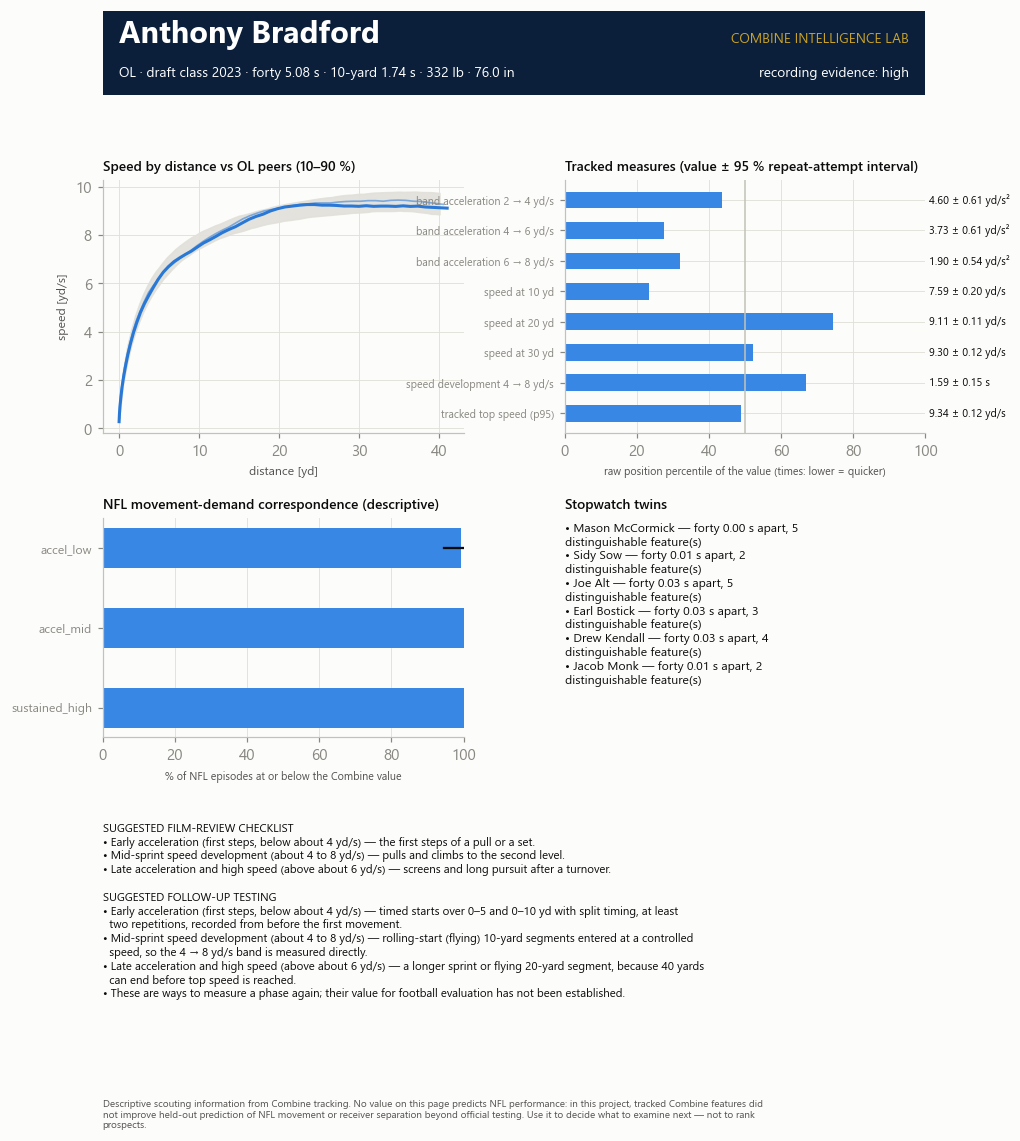

Send back: the validation table, the overview, figures AM09F_01–03 and the generated reading.
Interactive version: see apps/combine_intelligence_lab/README.md. Next: 09g_competition_presentation_package.ipynb


In [6]:
oriented = []
for r in mine.iter_rows(named=True):
    a_is_me = r['nfl_id_a'] == NID
    oriented.append({**r, 'other_name': r['name_b'] if a_is_me else r['name_a'], 'd_forty': r['d_forty'] if a_is_me else -r['d_forty']})
sections = sin.prospect_report(P, MET, oriented, MAT, list(EV.values()))
display(Markdown('\n\n'.join('**' + k + '**\n' + '\n'.join('- ' + s for s in v) for k, v in sections.items())))
my_curves = [(g['dist_yd'].to_numpy().astype(float), g['speed'].to_numpy().astype(float)) for _, g in
             T['combine_attempt_curves'].filter(pl.col('nfl_id') == NID).sort('attempt_order', 'frame').partition_by(['attempt_order'], as_dict=True, maintain_order=True).items()]
B = T['position_curve_bands'].filter(pl.col('position_group') == P['position_group']).sort('dist_yd')
band = {'grid': B['dist_yd'].to_numpy(), 'q10': B['q10'].to_numpy(), 'q50': B['q50'].to_numpy(), 'q90': B['q90'].to_numpy(), 'n': int(B['n_runs'][0])} if B.height else None
card = ifg.fig_intelligence_card(P, MET, oriented, MAT, my_curves, band, sections)
if controls.save_tables:
    out = store.reports_dir / 'demo'
    out.mkdir(parents=True, exist_ok=True)
    card.savefig(out / f'intelligence_card_{NID}.pdf')
    card.savefig(out / f'intelligence_card_{NID}.png', dpi=200)
    page = sin.render_html(NAME, f'{P["position_group"]} · class {P["draft_year"]} · prospect intelligence report', sections,
                           tables=[('Tracked measures', MET, ['label', 'unit', 'value', 'standard_error', 'n_attempts', 'pct_position', 'state'])],
                           footer=f'Combine Intelligence Lab · mart {MANIFEST["mart_version"]} built {MANIFEST["built_at"]} · run mode {controls.run_mode}')
    (out / f'prospect_report_{NID}.html').write_text(page, encoding='utf-8')
    print('written:', cfg.paths.rel(out / f'prospect_report_{NID}.html'), '·', cfg.paths.rel(out / f'intelligence_card_{NID}.pdf'))
store.show(card, f'AM09F_03_intelligence_card_{NID}', {}, publication=True, source='application mart', n='one prospect')
print('Send back: the validation table, the overview, figures AM09F_01–03 and the generated reading.')
print('Interactive version: see apps/combine_intelligence_lab/README.md. Next: 09g_competition_presentation_package.ipynb')